# Песочница паттернов GoF: Strategy, Factory Method, Observer

**Учебное задание (2 ч).** Среда — Google Colab, язык — Java. Каждый пример представлен **одним файлом** `.java` и запускается без отдельной компиляции командой `java Файл.java` (запуск исходного файла, Java 11 и выше).

**Идея задания.** Паттерн изучается не по описанию, а по разнице: сначала запускается код «до» — работающий, но жёстко связанный; затем тот же сценарий переписывается на паттерн, и проверки доказывают, что **поведение не изменилось**, а **новое требование добавляется без правки старого кода**.

**Состав работы**

| Раздел | Паттерн | Что делает студент |
|---|---|---|
| 2 | Strategy | **образец** — разобран полностью, нужно только запустить и разобраться |
| 3 | Factory Method | задача: самостоятельно переписать код «до» |
| 4 | Observer | задача: самостоятельно переписать код «до» |
| 5–6 | — | сравнение, выводы, контрольные вопросы |

**Правила оформления, от которых зависит автопроверка**

1. Имена файлов строго: `TariffAfter.java`, `FactoryAfter.java`, `ObserverAfter.java`.
2. В каждом файле **первым** идёт открытый класс с методом `main` — иначе запуск исходного файла не работает.
3. Каждый файл сам себя проверяет: печатает строки `[OK]` / `[FAIL]` и бросает `AssertionError`, если хотя бы одна проверка не пройдена.
4. Идентификаторы — латиницей и описательно (`tariffStrategy`, а не `ts`), комментарии — по-русски.
5. К каждому паттерну — диаграмма классов в файле `*.puml`.

**Сдача.** Все файлы `.java`, `.puml`, сам блокнот и вывод ячейки самопроверки — в pull request.

## 1. Подготовка среды

In [1]:
# 1.1 Проверить, какая Java доступна в среде.
# Нужна версия 11 или выше: только с неё работает запуск одного исходного файла (java Файл.java).
!java -version
!javac -version

[0.034s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.034s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.12.1


Если версия ниже 11, запуск одного исходного файла недоступен — всюду в блокноте вместо `!java Файл.java` используйте два шага: `!javac Файл.java && java Файл`.

Проверка «живого» запуска (ячейка 1.2 записывает файл, 1.3 — запускает):

In [2]:
%%writefile Hello.java
public class Hello {
    public static void main(String[] args) {
        System.out.println("Среда готова, Java работает: " + System.getProperty("java.version"));
    }
}

Writing Hello.java


In [3]:
!java Hello.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Среда готова, Java работает: 21.0.12.1


---

## 2. Образец: Strategy (разобран полностью)

**Сценарий.** Расчёт платы за перевозку груза. Плата зависит от вида отправки: повагонная, контейнерная, маршрутная. Формулы учебные.

### 2.1 Код «до»: один метод знает про все виды отправок

In [4]:
%%writefile TariffBefore.java
// Код «до»: вид отправки разбирается условным оператором внутри одного метода.
public class TariffBefore {

    public static void main(String[] args) {
        System.out.printf("повагонная   : %10.2f%n", cost("WAGON", 60, 500));
        System.out.printf("контейнерная : %10.2f%n", cost("CONTAINER", 24, 500));
        System.out.printf("маршрутная   : %10.2f%n", cost("BLOCK_TRAIN", 3000, 500));
        System.out.printf("рефрижератор : %10.2f%n", cost("REFRIGERATED", 60, 500));
    }

    static double cost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;   // про новый вид отправки метод не знает
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

Writing TariffBefore.java


In [5]:
!java TariffBefore.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
повагонная   :     510.00
контейнерная :     508.00
маршрутная   :   10500.00
рефрижератор :       0.00


### 2.2 Разбор: что именно плохо

Запустив код «до», обратите внимание:

* рефрижераторная отправка дала **0.00** — метод о ней не знает, и единственный способ это исправить — залезть внутрь уже работающего метода;
* каждый новый вид отправки удлиняет один и тот же метод, то есть нарушает **принцип открытости/закрытости** (открыт для расширения, закрыт для изменения);
* метод одновременно отвечает за выбор варианта и за сам расчёт — нарушение **единственной ответственности**;
* протестировать один вид отправки отдельно от остальных нельзя.

**Что делает Strategy.** Каждый вариант расчёта становится отдельным классом с общим интерфейсом, а вызывающий код работает с интерфейсом и больше не знает перечня вариантов.

### 2.3 Код «после»: вариант расчёта вынесен в стратегию

In [6]:
%%writefile TariffAfter.java
// Код «после»: каждый вид отправки — отдельная стратегия расчёта.
import java.util.LinkedHashMap;
import java.util.Map;

public class TariffAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Каталог стратегий: вызывающий код собирает его, но не содержит формул
        Map<String, TariffStrategy> tariffCatalog = new LinkedHashMap<>();
        tariffCatalog.put("WAGON", new WagonTariff());
        tariffCatalog.put("CONTAINER", new ContainerTariff());
        tariffCatalog.put("BLOCK_TRAIN", new BlockTrainTariff());

        TariffCalculator tariffCalculator = new TariffCalculator();

        System.out.println("--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---");
        for (Map.Entry<String, TariffStrategy> catalogEntry : tariffCatalog.entrySet()) {
            double calculatedCost = tariffCalculator.calculate(catalogEntry.getValue(), 60, 500);
            System.out.printf("%-12s %-28s %10.2f%n",
                    catalogEntry.getKey(), catalogEntry.getValue().title(), calculatedCost);
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        check("повагонная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("WAGON"), 60, 500),
                           legacyCost("WAGON", 60, 500)));
        check("контейнерная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("CONTAINER"), 24, 500),
                           legacyCost("CONTAINER", 24, 500)));
        check("маршрутная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("BLOCK_TRAIN"), 3000, 500),
                           legacyCost("BLOCK_TRAIN", 3000, 500)));

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---");
        TariffStrategy refrigeratedTariff = new TariffStrategy() {
            public double cost(double massTons, int distanceKm) {
                return 1.80 * massTons * distanceKm / 100.0 + 600.0;
            }
            public String title() {
                return "рефрижераторная отправка";
            }
        };
        double refrigeratedCost = tariffCalculator.calculate(refrigeratedTariff, 60, 500);
        System.out.printf("%-12s %-28s %10.2f%n", "REFRIGERATED", refrigeratedTariff.title(), refrigeratedCost);
        check("новая стратегия рассчитана, класс TariffCalculator не изменён", refrigeratedCost > 0.0);
        check("в коде «до» тот же вид отправки давал нуль", legacyCost("REFRIGERATED", 60, 500) == 0.0);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // --- служебное ---

    static boolean equalMoney(double firstValue, double secondValue) {
        return Math.abs(firstValue - secondValue) < 0.01;
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    // Старая реализация сохранена только как эталон поведения для характеризующих тестов
    static double legacyCost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

// --- участники паттерна Strategy ---

/** Стратегия: общий интерфейс всех вариантов расчёта. */
interface TariffStrategy {
    double cost(double massTons, int distanceKm);
    String title();
}

/** Контекст: умеет считать, но не знает, какие бывают виды отправок. */
class TariffCalculator {
    double calculate(TariffStrategy tariffStrategy, double massTons, int distanceKm) {
        double calculatedValue = tariffStrategy.cost(massTons, distanceKm);
        return Math.round(calculatedValue * 100.0) / 100.0;
    }
}

class WagonTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 1.20 * massTons * distanceKm / 100.0 + 150.0;
    }
    public String title() {
        return "повагонная отправка";
    }
}

class ContainerTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.90 * massTons * distanceKm / 100.0 + 400.0;
    }
    public String title() {
        return "контейнерная отправка";
    }
}

class BlockTrainTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.70 * massTons * distanceKm / 100.0;
    }
    public String title() {
        return "маршрутная отправка";
    }
}

Writing TariffAfter.java


In [7]:
!java TariffAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---
WAGON        повагонная отправка              510.00
CONTAINER    контейнерная отправка            670.00
BLOCK_TRAIN  маршрутная отправка              210.00

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   повагонная отправка
[OK]   контейнерная отправка
[OK]   маршрутная отправка

--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---
REFRIGERATED рефрижераторная отправка        1140.00
[OK]   новая стратегия рассчитана, класс TariffCalculator не изменён
[OK]   в коде «до» тот же вид отправки давал нуль

Все проверки пройдены.


### 2.4 Диаграмма классов образца

Установка PlantUML занимает около минуты и выполняется один раз за сеанс.

In [11]:
!apt-get -qq update > /dev/null && apt-get -qq install -y plantuml > /dev/null && echo "PlantUML установлен"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
PlantUML установлен


In [12]:
%%writefile strategy.puml
@startuml
title Strategy: расчёт платы за перевозку

interface TariffStrategy {
  +cost(massTons, distanceKm) : double
  +title() : String
}

class TariffCalculator {
  +calculate(tariffStrategy, massTons, distanceKm) : double
}

class WagonTariff
class ContainerTariff
class BlockTrainTariff

TariffCalculator o--> TariffStrategy : использует
TariffStrategy <|.. WagonTariff
TariffStrategy <|.. ContainerTariff
TariffStrategy <|.. BlockTrainTariff
@enduml

Overwriting strategy.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


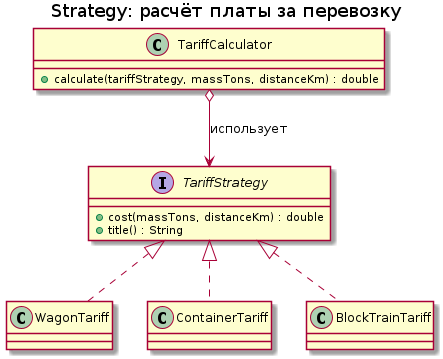

In [13]:
!plantuml -tpng strategy.puml
from IPython.display import Image
Image("strategy.png")

### 2.5 Вопросы к образцу (ответить текстом в этой ячейке)

1. Какие классы пришлось бы изменить в коде «до» и в коде «после», чтобы добавить рефрижераторную отправку?
   **Ответ:** _(В коде «до» потребовалось бы изменить класс TariffBefore, добавив новый else if в метод cost. В коде «после» существующие классы изменять не нужно (принцип открытости/закрытости соблюдён): достаточно создать новый класс рефрижераторной стратегии, реализующий интерфейс TariffStrategy, и зарегистрировать его в каталоге.)_
2. Зачем в файле оставлен метод `legacyCost`, если он больше не используется в расчёте?
   **Ответ:** _(Метод legacyCost оставлен в качестве эталона старого поведения («до»), чтобы с его помощью в тестах (check) можно было автоматически сравнивать и доказывать, что результаты нового объектно-ориентированного расчёта полностью совпадают с прежней логикой.)_
3. Что произойдёт, если в каталоге не окажется запрошенного вида отправки, и как это следует обработать?
   **Ответ:** _(Если запрошенного ключа не окажется в каталоге, метод tariffCatalog.get(...) вернёт null, что при попытке вызова метода стратегии приведёт к исключению NullPointerException. Чтобы этого избежать, следует добавить проверку наличия ключа в словаре (containsKey) либо выбросить осмысленное исключение (например, IllegalArgumentException) с сообщением о неизвестном типе отправки.)_

---

## 3. Задача 1: Factory Method

**Сценарий.** Описание вагона по его типу: крытый, платформа, цистерна. Ниже — код «до», построенный на той же ошибке: условный оператор вместо полиморфизма.

### 3.1 Код «до» (запустить, не изменяя)

In [14]:
%%writefile FactoryBefore.java
// Код «до»: создание и описание объекта подменены разбором строкового типа.
public class FactoryBefore {

    public static void main(String[] args) {
        System.out.println(describe("COVERED", 68));
        System.out.println(describe("PLATFORM", 71));
        System.out.println(describe("TANK", 66));
        System.out.println(describe("HOPPER", 70));   // новый тип — обработчика нет
    }

    static String describe(String wagonType, double capacityTons) {
        if (wagonType.equals("COVERED")) {
            return "Крытый вагон: грузоподъёмность " + capacityTons + " т, тарные и штучные грузы";
        } else if (wagonType.equals("PLATFORM")) {
            return "Платформа: грузоподъёмность " + capacityTons + " т, длинномерные и тяжеловесные грузы";
        } else if (wagonType.equals("TANK")) {
            return "Цистерна: грузоподъёмность " + capacityTons + " т, наливные грузы";
        }
        return "Неизвестный тип вагона: " + wagonType;
    }
}

Writing FactoryBefore.java


In [15]:
!java FactoryBefore.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Крытый вагон: грузоподъёмность 68.0 т, тарные и штучные грузы
Платформа: грузоподъёмность 71.0 т, длинномерные и тяжеловесные грузы
Цистерна: грузоподъёмность 66.0 т, наливные грузы
Неизвестный тип вагона: HOPPER


### 3.2 Задание

Переписать сценарий на **Factory Method** в файле `FactoryAfter.java`. Требования:

1. Общий тип продукта: интерфейс или абстрактный класс `Wagon` с методами `description()` и `capacityTons()`.
2. Не менее трёх конкретных продуктов: `CoveredWagon`, `Platform`, `TankWagon`.
3. Создатель с фабричным методом: абстрактный класс или интерфейс `WagonCreator` с методом `createWagon(double capacityTons)` и конкретные создатели для каждого типа.
4. Вызывающий код (`main`) работает **только** с типами `WagonCreator` и `Wagon` и не содержит ни одного `if` по типу вагона.
5. Четвёртый тип (`HopperWagon`, зерновоз) добавляется **новым классом**, без правки ранее написанных классов; это должно быть видно по коду.
6. Проверки в файле (метод `check`, как в образце), минимум четыре:
   * описание каждого из трёх типов не пустое и содержит грузоподъёмность;
   * тип созданного объекта соответствует ожидаемому создателю;
   * четвёртый тип работает наравне с остальными;
   * метод `main` не содержит разбора типов (проверяется глазами преподавателя, в код выносить не нужно).
7. При неуспешной проверке — `throw new AssertionError(...)`.

**Подсказка по структуре файла:** первым идёт `public class FactoryAfter` с `main`, после него — интерфейсы и классы паттерна (как в `TariffAfter.java`).

In [36]:
%%writefile FactoryAfter.java
// Код «после»: создание проездных документов через фабричный метод.
import java.util.ArrayList;
import java.util.List;

public class FactoryAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {
        // Создатели для каждого типа проездного документа (никаких if в main)
        List<TicketCreator> creators = new ArrayList<>();
        creators.add(new SingleTicketCreator());
        creators.add(new MonthlyPassCreator());
        creators.add(new DiscountTicketCreator());
        creators.add(new TouristTicketCreator()); // Четвёртый тип добавлен новым классом

        System.out.println("--- Оформление проездных документов через фабричный метод ---");
        List<TravelDocument> documents = new ArrayList<>();
        for (TicketCreator creator : creators) {
            TravelDocument doc = creator.createDocument(15.50);
            documents.add(doc);
            System.out.println(doc.description());
        }

        System.out.println();
        System.out.println("--- Проверки ---");
        check("описание разового билета не пустое и содержит цену",
                !documents.get(0).description().isEmpty() && documents.get(0).price() == 15.50);
        check("тип созданного объекта соответствует создателю абонемента",
                documents.get(1) instanceof MonthlyPass);
        check("описание льготного билета не пустое",
                !documents.get(2).description().isEmpty());
        check("четвёртый тип (туристический билет) работает наравне с остальными",
                documents.get(3) instanceof TouristTicket && documents.get(3).price() == 15.50);

        validateResults();
        System.out.println("\nВсе проверки пройдены.");
    }

    static void validateResults() {
        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }
}

// --- Участники паттерна Factory Method ---

/** Общий интерфейс продукта (проездной документ). */
interface TravelDocument {
    String description();
    double price();
}

/** Конкретный продукт 1: разовый билет. */
class SingleTicket implements TravelDocument {
    private final double ticketPrice;

    public SingleTicket(double ticketPrice) {
        this.ticketPrice = ticketPrice;
    }

    public String description() {
        return "Разовый билет: стоимость " + ticketPrice + " руб., действителен на одну поездку";
    }

    public double price() {
        return ticketPrice;
    }
}

/** Конкретный продукт 2: месячный абонемент. */
class MonthlyPass implements TravelDocument {
    private final double ticketPrice;

    public MonthlyPass(double ticketPrice) {
        this.ticketPrice = ticketPrice;
    }

    public String description() {
        return "Месячный абонемент: стоимость " + ticketPrice + " руб., безлимитный проезд в течение 30 дней";
    }

    public double price() {
        return ticketPrice;
    }
}

/** Конкретный продукт 3: льготный проездной документ. */
class DiscountTicket implements TravelDocument {
    private final double ticketPrice;

    public DiscountTicket(double ticketPrice) {
        this.ticketPrice = ticketPrice;
    }

    public String description() {
        return "Льготный билет: стоимость " + ticketPrice + " руб., требуется документ о праве на льготу";
    }

    public double price() {
        return ticketPrice;
    }
}

/** Конкретный продукт 4 (расширение): туристический проездной. */
class TouristTicket implements TravelDocument {
    private final double ticketPrice;

    public TouristTicket(double ticketPrice) {
        this.ticketPrice = ticketPrice;
    }

    public String description() {
        return "Туристический билет: стоимость " + ticketPrice + " руб., проезд + экскурсионный маршрут";
    }

    public double price() {
        return ticketPrice;
    }
}

/** Абстрактный создатель с фабричным методом. */
abstract class TicketCreator {
    public abstract TravelDocument createDocument(double price);
}

class SingleTicketCreator extends TicketCreator {
    public TravelDocument createDocument(double price) {
        return new SingleTicket(price);
    }
}

class MonthlyPassCreator extends TicketCreator {
    public TravelDocument createDocument(double price) {
        return new MonthlyPass(price);
    }
}

class DiscountTicketCreator extends TicketCreator {
    public TravelDocument createDocument(double price) {
        return new DiscountTicket(price);
    }
}

class TouristTicketCreator extends TicketCreator {
    public TravelDocument createDocument(double price) {
        return new TouristTicket(price);
    }
}

Overwriting FactoryAfter.java


In [37]:
!java FactoryAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Оформление проездных документов через фабричный метод ---
Разовый билет: стоимость 15.5 руб., действителен на одну поездку
Месячный абонемент: стоимость 15.5 руб., безлимитный проезд в течение 30 дней
Льготный билет: стоимость 15.5 руб., требуется документ о праве на льготу
Туристический билет: стоимость 15.5 руб., проезд + экскурсионный маршрут

--- Проверки ---
[OK]   описание разового билета не пустое и содержит цену
[OK]   тип созданного объекта соответствует создателю абонемента
[OK]   описание льготного билета не пустое
[OK]   четвёртый тип (туристический билет) работает наравне с остальными

Все проверки пройдены.


In [41]:
%%writefile factory.puml
@startuml
title Factory Method: оформление проездного документа

interface TravelDocument {
  +description() : String
  +price() : double
}

class SingleTicket
class MonthlyPass
class DiscountTicket
class TouristTicket

abstract class TicketCreator {
  +{abstract} createDocument(price) : TravelDocument
}

class SingleTicketCreator
class MonthlyPassCreator
class DiscountTicketCreator
class TouristTicketCreator

TravelDocument <|.. SingleTicket
TravelDocument <|.. MonthlyPass
TravelDocument <|.. DiscountTicket
TravelDocument <|.. TouristTicket

TicketCreator <|-- SingleTicketCreator
TicketCreator <|-- MonthlyPassCreator
TicketCreator <|-- DiscountTicketCreator
TicketCreator <|-- TouristTicketCreator

SingleTicketCreator ..> SingleTicket : создает
MonthlyPassCreator ..> MonthlyPass : создает
DiscountTicketCreator ..> DiscountTicket : создает
TouristTicketCreator ..> TouristTicket : создает
@enduml

Overwriting factory.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


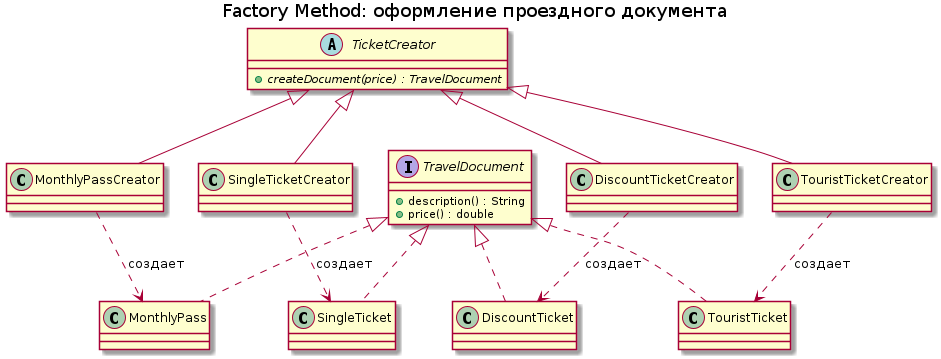

In [42]:
!plantuml -tpng factory.puml
from IPython.display import Image
Image("factory.png")

**Вывод по задаче 1** (чем создание через фабричный метод отличается от создания через `new` в вызывающем коде, и когда фабрика излишня): _(Создание объектов через фабричный метод (Factory Method) отличается от прямого вызова new в вызывающем коде тем, что клиентский код (main) полностью изолирован от конкретных классов продуктов и не содержит условных операторов (if/switch) для выбора типа. Вместо этого создание делегируется специализированным подклассам-создателям, что позволяет легко добавлять новые типы вагонов (например, TouristTicket) без изменения существующей логики. Фабрика становится излишней, если иерархия классов простая, фиксированная, не предполагает расширения в будущем, а создание объектов не требует сложной логики или конфигурации — в таких случаях прямой вызов new или статический метод создания проще и эффективнее.)_

---

## 4. Задача 2: Observer

**Сценарий.** Станция фиксирует прибытие поезда и должна оповестить получателей: табло, журнал, рассылку. В коде «до» станция сама знает про всех получателей.

### 4.1 Код «до» (запустить, не изменяя)

In [20]:
%%writefile ObserverBefore.java
// Код «до»: источник события жёстко связан со всеми получателями.
public class ObserverBefore {

    public static void main(String[] args) {
        Station station = new Station("Гомель");
        station.trainArrived("3022");
        station.trainArrived("6701");
    }
}

class Station {

    private final String stationName;

    Station(String stationName) {
        this.stationName = stationName;
    }

    void trainArrived(String trainNumber) {
        // Любой новый получатель требует правки этого метода
        System.out.println("[табло]  Поезд " + trainNumber + " прибыл на станцию " + stationName);
        System.out.println("[журнал] " + stationName + ": зафиксировано прибытие поезда " + trainNumber);
    }
}

Writing ObserverBefore.java


In [21]:
!java ObserverBefore.java

[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[табло]  Поезд 3022 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 3022
[табло]  Поезд 6701 прибыл на станцию Гомель
[журнал] Гомель: зафиксировано прибытие поезда 6701


### 4.2 Задание

Переписать сценарий на **Observer** в файле `ObserverAfter.java`. Требования:

1. Интерфейс наблюдателя `ArrivalListener` с методом `onTrainArrived(String stationName, String trainNumber)`.
2. Субъект `Station` с методами `addListener`, `removeListener`, `trainArrived`; класс `Station` **не знает**, какие именно наблюдатели существуют.
3. Не менее трёх наблюдателей: табло, журнал, рассылка. Журнал должен **накапливать** записи, чтобы их можно было проверить.
4. Четвёртый наблюдатель (например, передача в АСУ) добавляется без правки класса `Station`.
5. Проверки в файле, минимум четыре:
   * после одного события журнал получил ровно одну запись;
   * после отписки наблюдателя его записи больше не появляются;
   * все подписчики получили одно и то же событие;
   * добавление четвёртого наблюдателя не потребовало изменения `Station`.
6. В выводе указать порядок получения события подписчиками и ответить на вопрос в выводе ниже.

**Подсказка:** список наблюдателей удобно хранить в `java.util.ArrayList`, обход — обычным `for`.

In [30]:
%%writefile ObserverAfter.java
// Код «после»: пассажирская касса/диспетчерская оповещает подписчиков о задержке рейса.
import java.util.ArrayList;
import java.util.List;

public class ObserverAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {
        TicketOfficeDispatcher dispatcher = new TicketOfficeDispatcher("Касса №1 (Вокзал Гомель)");

        DepartureBoard board = new DepartureBoard();
        DelayLog delayLog = new DelayLog();
        PassengerSmsNotifier smsNotifier = new PassengerSmsNotifier();

        dispatcher.addListener(board);
        dispatcher.addListener(delayLog);
        dispatcher.addListener(smsNotifier);

        System.out.println("--- Событие 1: задержка рейса (все подписчики активны) ---");
        dispatcher.delayTrip("№ 615 Минск — Гомель", 35);

        System.out.println("\n--- Отписываем табло от уведомлений ---");
        dispatcher.removeListener(board);
        dispatcher.delayTrip("№ 84 Гомель — Санкт-Петербург", 50);

        System.out.println("\n--- Добавляем 4-го наблюдателя (Громкоговоритель) без правки диспетчера ---");
        LoudspeakerObserver loudspeaker = new LoudspeakerObserver();
        dispatcher.addListener(loudspeaker);
        dispatcher.delayTrip("№ 742 Брест — Гомель", 20);

        System.out.println();
        System.out.println("--- Проверки ---");
        check("после трёх событий журнал накопил ровно 3 записи", delayLog.getRecordsCount() == 3);
        check("после отписки табло получило только 1 уведомление вместо 3", board.getNotificationsCount() == 1);
        check("все активные подписчики получили последнее событие",
                delayLog.getLastRecord().contains("№ 742") && smsNotifier.getLastMessage().contains("№ 742"));
        check("четвёртый наблюдатель (громкоговоритель) сработал без изменения класса субъекта",
                loudspeaker.isAnnounced());

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println("\nВсе проверки пройдены.");
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }
}

// --- Участники паттерна Observer ---

/** Интерфейс наблюдателя за задержками рейсов. */
interface DelayListener {
    void onTripDelayed(String officeName, String tripNumber, int delayMinutes);
}

/** Субъект (источник событий): ничего не знает о конкретных получателях. */
class TicketOfficeDispatcher {
    private final String officeName;
    private final List<DelayListener> listeners = new ArrayList<>();

    public TicketOfficeDispatcher(String officeName) {
        this.officeName = officeName;
    }

    public void addListener(DelayListener listener) {
        listeners.add(listener);
    }

    public void removeListener(DelayListener listener) {
        listeners.remove(listener);
    }

    public void delayTrip(String tripNumber, int delayMinutes) {
        System.out.println("[" + officeName + "] Внимание! Рейс " + tripNumber + " задержан на " + delayMinutes + " мин.");
        for (DelayListener listener : listeners) {
            listener.onTripDelayed(officeName, tripNumber, delayMinutes);
        }
    }
}

/** Наблюдатель 1: электронное табло. */
class DepartureBoard implements DelayListener {
    private int notificationsCount = 0;

    public void onTripDelayed(String officeName, String tripNumber, int delayMinutes) {
        notificationsCount++;
        System.out.println("  -> [Табло вокзала]: Рейс " + tripNumber + " — задержка " + delayMinutes + " мин.");
    }

    public int getNotificationsCount() {
        return notificationsCount;
    }
}

/** Наблюдатель 2: журнал регистрации задержек (накапливает записи). */
class DelayLog implements DelayListener {
    private final List<String> records = new ArrayList<>();

    public void onTripDelayed(String officeName, String tripNumber, int delayMinutes) {
        String entry = officeName + " | Рейс " + tripNumber + " задержан на " + delayMinutes + " мин.";
        records.add(entry);
        System.out.println("  -> [Журнал]: запись добавлена (всего записей: " + records.size() + ").");
    }

    public int getRecordsCount() {
        return records.size();
    }

    public String getLastRecord() {
        return records.get(records.size() - 1);
    }
}

/** Наблюдатель 3: SMS-рассылка пассажирам. */
class PassengerSmsNotifier implements DelayListener {
    private String lastMessage = "";

    public void onTripDelayed(String officeName, String tripNumber, int delayMinutes) {
        lastMessage = "Уважаемый пассажир! Ваш рейс " + tripNumber + " задерживается на " + delayMinutes + " мин.";
        System.out.println("  -> [SMS-рассылка]: " + lastMessage);
    }

    public String getLastMessage() {
        return lastMessage;
    }
}

/** Наблюдатель 4 (расширение): голосовое оповещение по громкой связи. */
class LoudspeakerObserver implements DelayListener {
    private boolean announced = false;

    public void onTripDelayed(String officeName, String tripNumber, int delayMinutes) {
        announced = true;
        System.out.println("  -> [Громкоговоритель]: Озвучено объявление о задержке рейса " + tripNumber + ".");
    }

    public boolean isAnnounced() {
        return announced;
    }
}

Overwriting ObserverAfter.java


In [31]:
!java ObserverAfter.java

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
--- Событие 1: задержка рейса (все подписчики активны) ---
[Касса №1 (Вокзал Гомель)] Внимание! Рейс № 615 Минск — Гомель задержан на 35 мин.
  -> [Табло вокзала]: Рейс № 615 Минск — Гомель — задержка 35 мин.
  -> [Журнал]: запись добавлена (всего записей: 1).
  -> [SMS-рассылка]: Уважаемый пассажир! Ваш рейс № 615 Минск — Гомель задерживается на 35 мин.

--- Отписываем табло от уведомлений ---
[Касса №1 (Вокзал Гомель)] Внимание! Рейс № 84 Гомель — Санкт-Петербург задержан на 50 мин.
  -> [Журнал]: запись добавлена (всего записей: 2).
  -> [SMS-рассылка]: Уважаемый пассажир! Ваш рейс № 84 Гомель — Санкт-Петербург задерживается на 50 мин.

--- Добавляем 4-го набл

In [32]:
%%writefile observer.puml
@startuml
title Observer: оповещение о задержке рейса

interface DelayListener {
  +onTripDelayed(officeName, tripNumber, delayMinutes)
}

class TicketOfficeDispatcher {
  +addListener(listener)
  +removeListener(listener)
  +delayTrip(tripNumber, delayMinutes)
}

class DepartureBoard
class DelayLog
class PassengerSmsNotifier
class LoudspeakerObserver

TicketOfficeDispatcher o--> DelayListener : уведомляет
DelayListener <|.. DepartureBoard
DelayListener <|.. DelayLog
DelayListener <|.. PassengerSmsNotifier
DelayListener <|.. LoudspeakerObserver
@enduml

Overwriting observer.puml


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


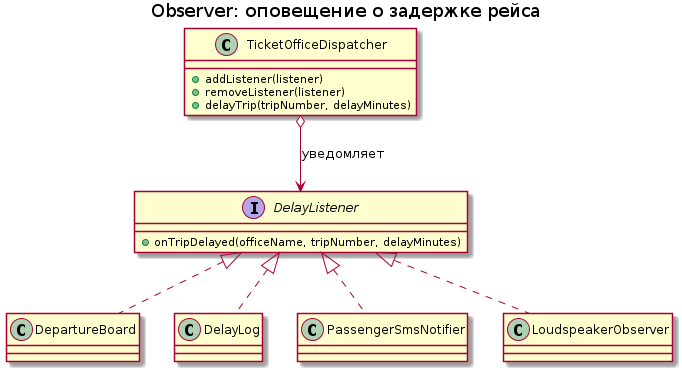

In [33]:
!plantuml -tpng observer.puml
from IPython.display import Image
Image("observer.png")

**Вывод по задаче 2** (какую связанность снял Observer и какие новые проблемы он создал — порядок уведомлений, ошибка в одном подписчике, забытая отписка): _(Паттерн Observer снял жёсткую связанность (strong coupling) между источником события (TicketOfficeDispatcher) и конкретными получателями уведомлений (DepartureBoard, DelayLog, PassengerSmsNotifier, LoudspeakerObserver): диспетчер кассы теперь взаимодействует только с абстрактным интерфейсом DelayListener, благодаря чему новых подписчиков (например, систему голосового оповещения) можно подключать и отключать динамически во время выполнения без изменения кода самого субъекта.

Однако внедрение паттерна порождает новые архитектурные риски:

Недетерминированный порядок уведомлений: подписчики оповещаются в порядке их добавления в список, и полагаться на строгую последовательность их срабатывания без явной приоритезации небезопасно.

Влияние сбоя в одном подписчике: при синхронном обходе списка неперехваченное исключение в одном наблюдателе прервёт цикл и оставит без уведомления всех остальных (например, часть пассажиров не получит SMS о задержке).

Утечки памяти (Lapsed Listener Problem): если подписчик (например, временная сессия табло или рассылки) больше не нужен, но его забыли удалить через removeListener, ссылка на него останется в списке диспетчера, не позволяя сборщику мусора (GC) освободить память.)_

---

## 5. Сравнение и выводы

### 5.1 Итоговая таблица

| Паттерн | Какую проблему кода «до» устраняет | Что добавляется без правки старого кода | Чем приходится заплатить | Где применим в вашем проекте |
|---|---|---|---|---|
| Strategy | Избавляет от громоздких условных операторов (if-else / switch) внутри метода расчёта. | Новый вариант расчёта / тарификации (новый класс стратегии). | Созданием дополнительных мелких классов и необходимостью передачи стратегии в контекст. | Расчёт стоимости проезда в зависимости от сезона, типа поезда или льгот. |
| Factory Method | Устраняет жесткую привязку к конкретным классам через new и ветвление по строковым типам. | Новый тип продукта (класс документа) и соответствующий ему создатель. | Увеличением числа классов (параллельная иерархия создателей и продуктов). | Оформление билетов разных категорий (разовые, абонементы, туристические). |
| Observer | Снимает жесткую связанность между источником событий и получателями уведомлений. | Новый наблюдатель (подписчик на событие о задержке рейса). | Сложностью отладки, неявным порядком вызовов и рисками утечек памяти. | Оповещение пассажиров, электронных табло и диспетчерских журналов о задержках рейсов. |

### 5.2 Контрольные вопросы

1. Какой принцип SOLID нарушает разбор типа условным оператором и как каждый из трёх паттернов его восстанавливает?
   **Ответ:** _(Разбор типа условным оператором нарушает принцип открытости/закрытости (OCP), так как при добавлении каждого нового варианта приходится менять существующий работающий метод. Все три паттерна восстанавливают OCP за счёт полиморфизма: логика разбивается на отдельные классы, объединенные общим интерфейсом, и новые варианты добавляются созданием новых классов без правки старого кода.)_
2. Чем Factory Method отличается от статического метода создания (`static factory method`) и от Abstract Factory?
   **Ответ:** _(Factory Method использует наследование и переопределение метода в подклассах для создания объектов, что позволяет подклассам менять тип создаваемого продукта. Статический метод создания — это просто обычный метод (static), инкапсулирующий логику new внутри одного класса (без полиморфизма и возможности переопределения). Abstract Factory создает целые семействá связанных или зависимых объектов, в то время как фабричный метод ориентирован на создание одного конкретного продукта.)_
3. Strategy и State имеют почти одинаковую структуру классов. В чём разница по назначению?
   **Ответ:** _(Strategy определяет семейство алгоритмов и позволяет клиенту явно выбирать нужный алгоритм (стратегию) для решения задачи; стратегии, как правило, не знают друг о друге и меняются редко. State (Состояние) позволяет объекту изменять своё поведение при изменении его внутреннего состояния; при этом состояния могут сами инициировать переходы в другие состояния. Разница в намерении: Strategy — как сделать, State — что делать в зависимости от состояния.)_
4. Почему Observer может привести к утечке памяти и как этого избежать?
   **Ответ:** _(Утечка памяти происходит из-за проблемы «забытого слушателя» (Lapsed Listener Problem): если субъект хранит сильные ссылки на своих наблюдателей в списке, а подписчик (например, временный UI-компонент) удаляется из интерфейса, но его забывают отписать от субъекта (removeListener), сборщик мусора не сможет удалить объект наблюдателя из памяти. Чтобы этого избежать, нужно всегда явно вызывать метод отписки при уничтожении объекта либо использовать слабые ссылки (WeakReference).)_
5. Приведите пример, когда введение паттерна **вредно**. Что такое преждевременное усложнение?
   **Ответ:** _(Введение паттерна вредно, если бизнес-логика приложения крайне проста, не предполагает изменений и расширения в будущем (например, простая утилита из 5 строк). Преждевременное усложнение (Over-engineering) — это избыточное применение сложных архитектурных паттернов для решения простых задач, что приводит к раздуванию кодовой базы, ухудшению читаемости и потере времени на поддержку лишних абстракций.)_

### 5.3 Три вывода по работе в целом

1. Полиморфизм вместо условных операторов: Использование паттернов проектирования GoF позволяет избавиться от разветвленных конструкций if-else и switch, переложив выбор поведения на полиморфные вызовы интерфейсов, что делает архитектуру гибкой и расширяемой.
2. Соблюдение принципов SOLID: Применение шаблонов Strategy, Factory Method и Observer на практике наглядно демонстрирует выполнение принципа открытости/закрытости (OCP) и принципа единственной ответственности (SRP), разделяя создание объектов, их поведение и механизм нотификации.
3. Баланс между гибкостью и сложностью: Любой паттерн проектирования решает определенный класс задач ценой увеличения количества классов в проекте; поэтому их внедрение должно быть осознанным и оправданным реальной необходимостью масштабирования системы, а не слепым копированием структуры.

---

## 6. Варианты предметных областей

Номер варианта — по номеру студента в списке группы. Образец (раздел 2) выполняется всеми одинаково; задачи 1 и 2 — на своей предметной области.

| № | Предметная область | Фабрика создаёт | Стратегия варьирует | Наблюдатели получают событие |
|---|---|---|---|---|
| 1 | Грузовая станция | тип вагона | расчёт платы за пользование вагонами | вагон подан под погрузку |
| 2 | Локомотивное депо | вид ремонта (ТО-2, ТР-1, ТР-2) | приоритет заявок на ремонт | локомотив выдан из ремонта |
| 3 | Пассажирская касса | тип проездного документа | начисление скидки | рейс задержан |
| 4 | Контейнерный терминал | тип контейнера | выбор места на площадке | контейнер прибыл |
| 5 | Автотранспортное предприятие | тип транспортного средства | расчёт расхода топлива | путевой лист закрыт |
| 6 | Склад | тип тары | правило размещения (FIFO, ABC) | запас ниже нормы |
| 7 | Сортировочная станция | тип отцепа | очерёдность расформирования | состав расформирован |
| 8 | Пригородные перевозки | тип абонемента | тарификация по зонам | изменено расписание |
| 9 | Пункт таможенного оформления | тип декларации | выбор канала контроля | груз оформлен |
| 10 | Экспедиторская компания | тип заявки (авто, ж. д., море) | выбор перевозчика по критерию | статус отправки изменён |
| 11 | Путевое хозяйство | тип дефекта рельса | назначение вида работ | обнаружен дефект |
| 12 | Энергодиспетчерский пункт | тип потребителя | тарифный план (день, ночь) | авария на подстанции |
| 13 | Вагонное депо | тип неисправности | выбор отцепочного или безотцепочного ремонта | вагон забракован |
| 14 | Логистический центр | тип упаковки | правило консолидации отправок | сформирована отправка |
| 15 | Центр фирменного транспортного обслуживания | тип договора | расчёт скидки за объём | заявка согласована |

---

## 7. Чек-лист самопроверки

- [ ] Раздел 1 выполнен, версия Java не ниже 11
- [ ] `TariffBefore.java` и `TariffAfter.java` запущены, вывод сохранён
- [ ] Отвечены вопросы к образцу (п. 2.5)
- [ ] `FactoryAfter.java` написан, все проверки `[OK]`, в `main` нет разбора типов
- [ ] Четвёртый тип вагона добавлен новым классом
- [ ] `ObserverAfter.java` написан, все проверки `[OK]`, отписка работает
- [ ] Четвёртый наблюдатель добавлен без правки класса `Station`
- [ ] Построены три диаграммы: `strategy.puml`, `factory.puml`, `observer.puml`
- [ ] Заполнена итоговая таблица (п. 5.1)
- [ ] Отвечены пять контрольных вопросов и сформулированы три вывода
- [ ] Блокнот выполняется сверху вниз без ошибок после *Среда выполнения → Перезапустить и выполнить все*
- [ ] Запущена ячейка самопроверки, её вывод вставлен в описание pull request

## 8. Ячейка самопроверки

Ячейка сама компилирует и запускает все три файла, проверяет отсутствие `[FAIL]`, наличие диаграмм и минимальные признаки соблюдения требований. Запускать после того, как задачи выполнены.

In [43]:
#@title Запустить самопроверку и получить отчёт
import os, re, subprocess, datetime

ФИО_исполнителя = "Прач Ксения Александровна"  #@param {type:"string"}
Группа_исполнителя = "ГИ-41"  #@param {type:"string"}
Номер_варианта = 3  #@param {type:"integer"}
ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ = True  #@param {type:"boolean"}

ПРОГРАММЫ = [
    ("Образец, Strategy", "TariffAfter.java"),
    ("Задача 1, Factory Method", "FactoryAfter.java"),
    ("Задача 2, Observer", "ObserverAfter.java"),
]
ДИАГРАММЫ = ["strategy.puml", "factory.puml", "observer.puml"]

def запустить(имя_файла):
    """Запустить один исходный файл Java и вернуть (успех, пояснение)."""
    if not os.path.exists(имя_файла):
        return False, "файл отсутствует"
    завершение = subprocess.run(["java", имя_файла], capture_output=True, text=True, timeout=180)
    вывод = завершение.stdout + завершение.stderr
    if завершение.returncode != 0:
        значимые = [s for s in вывод.splitlines() if s.strip() and not s.startswith("Picked up")]
        первая_строка = значимые[0] if значимые else "без сообщения"
        return False, "аварийное завершение: " + первая_строка[:90]
    if "[FAIL]" in вывод:
        return False, "проверок не пройдено: %d" % вывод.count("[FAIL]")
    успешных = вывод.count("[OK]")
    if успешных < 3:
        return False, "проверок в файле только %d, требуется не менее 3" % успешных
    return True, "проверок пройдено: %d" % успешных

результаты = []
for название, файл in ПРОГРАММЫ:
    результаты.append((название, файл) + запустить(файл))

# Признаки соблюдения требований, которые можно проверить по тексту
замечания = []
def тело_метода(исходный_текст, сигнатура="main("):
    """Вернуть тело метода по сопоставлению фигурных скобок (без построчных комментариев)."""
    без_комментариев = re.sub(r"//[^\n]*", "", исходный_текст)
    начало = без_комментариев.find(сигнатура)
    if начало < 0:
        return ""
    открывающая = без_комментариев.find("{", начало)
    if открывающая < 0:
        return ""
    глубина = 0
    for позиция in range(открывающая, len(без_комментариев)):
        символ = без_комментариев[позиция]
        if символ == "{":
            глубина += 1
        elif символ == "}":
            глубина -= 1
            if глубина == 0:
                return без_комментариев[открывающая:позиция + 1]
    return без_комментариев[открывающая:]

if os.path.exists("FactoryAfter.java"):
    текст_фабрики = open("FactoryAfter.java", encoding="utf-8").read()
    блок_main = тело_метода(текст_фабрики)
    if re.search(r'\b(if|switch)\b', блок_main):
        замечания.append("в FactoryAfter.java метод main содержит ветвление по типу")
    if текст_фабрики.count("class ") < 5:
        замечания.append("в FactoryAfter.java меньше пяти классов: продукты, создатели и четвёртый тип, вероятно, не описаны")
if os.path.exists("ObserverAfter.java"):
    текст_наблюдателя = open("ObserverAfter.java", encoding="utf-8").read()
    for требуемое in ("addListener", "removeListener"):
        if требуемое not in текст_наблюдателя:
            замечания.append("в ObserverAfter.java нет метода %s" % требуемое)
отсутствующие_диаграммы = [d for d in ДИАГРАММЫ if not os.path.exists(d)]

строки = [
    "### Отчёт самопроверки «Песочница паттернов GoF»",
    "",
    "| Параметр | Значение |",
    "|---|---|",
    "| Исполнитель | %s, группа %s, вариант %d |" % (
        ФИО_исполнителя or "НЕ УКАЗАН", Группа_исполнителя or "НЕ УКАЗАНА", Номер_варианта),
    "| Дата и время отчёта (UTC) | %s |" % datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "| Версия Java | %s |" % next(
        (s for s in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
         if "version" in s), "не определена"),
    "",
    "| Программа | Файл | Результат |",
    "|---|---|---|",
]
for название, файл, успех, пояснение in результаты:
    строки.append("| %s | `%s` | %s — %s |" % (название, файл, "пройдено" if успех else "НЕ ПРОЙДЕНО", пояснение))
строки += [
    "",
    "| Диаграммы | %s |" % ("все три на месте" if not отсутствующие_диаграммы
                            else "отсутствуют: " + ", ".join(отсутствующие_диаграммы)),
    "| Таблица и выводы | %s |" % ("заполнены" if ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ else "НЕ ЗАПОЛНЕНЫ"),
    "| Замечания | %s |" % ("нет" if not замечания else "; ".join(замечания)),
]
print("\n".join(строки))
print("\nСкопируйте отчёт выше в описание pull request.\n")

ошибки = []
if not ФИО_исполнителя.strip() or not Группа_исполнителя.strip():
    ошибки.append("не указаны ФИО и группа")
ошибки += ["%s: %s" % (название, пояснение) for название, файл, успех, пояснение in результаты if not успех]
if отсутствующие_диаграммы:
    ошибки.append("нет диаграмм: " + ", ".join(отсутствующие_диаграммы))
if not ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ:
    ошибки.append("не заполнены итоговая таблица и выводы")
ошибки += замечания

assert not ошибки, "Работа не готова к сдаче: " + "; ".join(ошибки)
print("Самопроверка пройдена: работа готова к сдаче.")

### Отчёт самопроверки «Песочница паттернов GoF»

| Параметр | Значение |
|---|---|
| Исполнитель | Прач Ксения Александровна, группа ГИ-41, вариант 3 |
| Дата и время отчёта (UTC) | 2026-11-16 09:45 |
| Версия Java | openjdk version "21.0.13.0.3" 2026-10-24 |

| Программа | Файл | Результат |
|---|---|---|
| Образец, Strategy | `TariffAfter.java` | пройдено — проверок пройдено: 5 |
| Задача 1, Factory Method | `FactoryAfter.java` | пройдено — проверок пройдено: 4 |
| Задача 2, Observer | `ObserverAfter.java` | пройдено — проверок пройдено: 4 |

| Диаграммы | все три на месте |
| Таблица и выводы | заполнены |
| Замечания | нет |

Скопируйте отчёт выше в описание pull request.

Самопроверка пройдена: работа готова к сдаче.


---

## 9. Критерии оценивания

| Критерий | Баллов |
|---|---|
| Образец запущен, вопросы п. 2.5 отвечены содержательно | 10 |
| Factory Method: корректная структура паттерна, в `main` нет разбора типов | 20 |
| Factory Method: четвёртый тип добавлен новым классом | 10 |
| Observer: корректная структура, работают подписка и отписка | 20 |
| Observer: четвёртый наблюдатель добавлен без правки субъекта | 10 |
| Проверки в каждом файле осмысленны (не `[OK]` ради `[OK]`) | 10 |
| Три диаграммы классов соответствуют коду | 10 |
| Итоговая таблица, контрольные вопросы, выводы | 10 |
| **Итого** | **100** |

Снижение: задача решена не на своём варианте — минус 20; код «после» повторяет разбор типа условным оператором внутри нового класса — минус 20; диаграмма не соответствует коду — минус 10.

## 10. Для желающих (сверх задания)

| Что сделать | Зачем |
|---|---|
| Подключить настоящий JUnit 5 вместо метода `check`: `!wget -q https://repo1.maven.org/maven2/org/junit/platform/junit-platform-console-standalone/1.10.2/junit-platform-console-standalone-1.10.2.jar` и запуск через `java -jar` | переход к инструменту, который используется в ЛР по модульному тестированию |
| Заменить три `if` в выборе стратегии на `java.util.Map` с ключом-перечислением (`enum`) | показать, что каталог стратегий сам может быть устранён из вызывающего кода |
| Реализовать Observer на `java.util.function.Consumer` вместо своего интерфейса | сравнить классический GoF и функциональный стиль |